## Neural Networks and the Artificial Neuron

**What is a neural network?**

An **artificial neural network (ANN)** is a computational model loosely inspired by the brain. It consists of many simple processing units (neurons) connected in layers. Instead of being programmed with explicit rules, it **learns patterns from data** by adjusting the strengths of the connections between neurons.

A typical network has three kinds of layers:

**Input layer**: receives the raw data (pixels, words, sensor values).

**Hidden layer(s)**: transform the data step by step, extracting increasingly abstract features.

**Output layer**: produces the final result (a class label, a number, a probability).

A network with many hidden layers is called a **deep neural network**, which is where the term "deep learning" comes from.

**What is an artificial neuron?**

The artificial neuron is the basic building block. It mimics a biological neuron in a simplified way: it receives signals, combines them, and decides how strongly to "fire".

## Inputs, Weights, Bias, and Activation

These four components define exactly what a single neuron computes:

$y = f(W_1x_1 + W_2x_2 + ... + W_nx_n + b)$

1. **Inputs (x)**

Inputs are the numerical values fed into the neuron. They are either the raw features of the data (pixel intensity, age, temperature) or the outputs of neurons in the previous layer.

Inputs must be numbers, so text, images, and categories are converted to numeric form first. They are often **normalized** (scaled to a similar range) so that no single feature dominates just because its values are larger.

2. **Weights (w)**

Each input has its own weight, which controls **how much influence that input has** on the neuron's output.

**Large positive weight**: the input strongly pushes the neuron toward activating.
**Weight near zero**: the input is essentially ignored.
**Negative weight**: the input suppresses the neuron.

Weights are the **learnable parameters** of the network. They start as small random values and are adjusted during training. In effect, the network's 'knowledge' is stored in its weights.

3. **Bias (b)**

The bias is an extra learnable number added to the weighted sum. It is not tied to any input.

Its role is to **shift the activation threshold**. Without bias, a neuron with all-zero inputs would always produce $z=0$. With bias, the neuron can be made to fire even when inputs are small, or to stay quiet unless inputs are large.

Geometrically, in a 2D example, the weights set the **slope/direction** of the decision line, while the bias moves it away from the origin.

4. **Activation function (f)**

The activation function takes the sum $z = Σw_ix_i + b$ and produces the neuron's output. Its main purpose is to introduce **non-linearity**, which lets the network learn complex patterns rather than only straight-line relationships.

## What Decision Does a Perceptron Make?

A **perceptron** is the simplest neural network: a single neuron that makes a **binary decision**. It answers a yes/no question by assigning an input to one of two classes (for example 1 or 0, spam or not spam, pass or fail).

**How it decides**

Compute the weighted sum:

$z = W_1x_1+W_2x_2+...+W_nx_n + b$

Apply a **step function** as the activation:

$y = 1$ if $z ≥ 0$

$y = 0$ if $z < 0$

So the decision is simply: **is the weighted evidence strong enough to cross the threshold?** The bias sets how much evidence is needed.

**Geometric meaning: a decision boundary**

The equation **Wx + b = 0** defines a line (in 2D), a plane (in 3D), or a hyperplane (in higher dimensions). This is the **decision boundary**.

Points on one side of it are classified as **1**.
Points on the other side are classified as **0**.

The weights set the orientation of the boundary, and the bias shifts its position.

## Perceptron Example

A simple perceptron that learns to classify 0/1 (the OR function)

In [1]:
# Training data: inputs and their correct labels

X = [(0, 0), (0, 1), (1, 0), (1, 1)]
y = [0, 1, 1, 1]

# Start with zero weights and bias

w = [0.0, 0.0]
b = 0.0
lr = 0.1  # learning rate


def predict(x):
    z = w[0] * x[0] + w[1] * x[1] + b
    return 1 if z >= 0 else 0  # step activation


# Training loop

for epoch in range(20):
    errors = 0
    for xi, target in zip(X, y):
        error = target - predict(xi)
        if error != 0:
            w[0] += lr * error * xi[0]
            w[1] += lr * error * xi[1]
            b += lr * error
            errors += 1
    print(f"Epoch {epoch + 1}: errors = {errors}")
    if errors == 0: # learned perfectly
        break

print("\nLearned weights:", w, ", bias:", b)

# Test

for xi in X:
    print(f"Input {xi} --> predicted {predict(xi)}")

Epoch 1: errors = 2
Epoch 2: errors = 2
Epoch 3: errors = 1
Epoch 4: errors = 0

Learned weights: [0.1, 0.1] , bias: -0.1
Input (0, 0) --> predicted 0
Input (0, 1) --> predicted 1
Input (1, 0) --> predicted 1
Input (1, 1) --> predicted 1


## The XOR Problem

What is XOR?

**XOR** (exclusive OR) outputs **1 only when the two inputs differ**:

```
x₁	x₂	 XOR
-------------
0	0	  0
0	1	  1
1	0	  1
1	1	  0
```

**Why a single perceptron fails**:

Plot the four points in 2D. Class 1 sits at (0,1) and (1,0); class 0 sits at (0,0) and (1,1). The two classes lie on **opposite diagonals of a square**, so no single straight line can put both class-1 points on one side and both class-0 points on the other.

**The solution: add a hidden layer**

XOR can be decomposed into simpler linearly separable pieces:

**XOR($x_1, x_2$) = AND( OR($x_1, x_2$), NAND($x_1, x_2$) )**

Hidden neuron 1 computes OR

Hidden neuron 2 computes NAND

Output neuron computes AND of those two

Each piece is linearly separable, so each neuron can handle it. The hidden layer **transforms the inputs into a new space** where the classes become separable by a line.

In [2]:
import numpy as np

def step(z):
    return (z >= 0).astype(int)

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

# Hidden layer: neuron 1 = OR, neuron 2 = NAND
W1 = np.array([[1, -1],
               [1, -1]])
b1 = np.array([-1, 1.5])

# Output layer: AND
W2 = np.array([1, 1])
b2 = -2

hidden = step(X @ W1 + b1)
output = step(hidden @ W2 + b2)

for xi, h, o in zip(X, hidden, output):
    print(xi, "-> hidden", h, "-> XOR", o)

[0 0] -> hidden [0 1] -> XOR 0
[0 1] -> hidden [1 1] -> XOR 1
[1 0] -> hidden [1 1] -> XOR 1
[1 1] -> hidden [1 0] -> XOR 0


## Activation Function

An activation function takes the neuron's weighted sum **$z = wx + b$** and produces its output **y = f(z)**. Its main job is to introduce **non-linearity**. Without it, any stack of layers collapses into one linear transformation, and the network could not learn XOR or any other complex pattern.

A good activation function is usually non-linear, differentiable (so backpropagation works), and cheap to compute.

**1. Step function (Binary threshold)**

**$f(z) = 1$ if $z ≥ 0$, else $0$**

- Used in the original perceptron.
- Gradient is zero almost everywhere, so **it cannot be trained with backpropagation**.
- Rarely used today.

**2. Sigmoid (Logistic)**

**$f(z) = \frac{1}{1+e^{-z}}$**, range (0, 1)

- Smooth S-shaped curve; output can be read as a probability.

- Common in the output layer for **binary classification**.

- **Drawbacks**: vanishing gradients for large $|z|$, outputs are not zero-centered, and it is relatively expensive to compute.

**3. Tanh (Hyperbolic tangent)**

$f(z) = \frac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$, range (-1, 1)

- Like sigmoid but **zero-centered**, which usually makes training easier.

- Still suffers from vanishing gradients at the extremes.

- Common in recurrent networks (RNN, LSTM).

**4. ReLU (Rectified Linear Unit)**

**$f(z) = max(0, z)$**, range [0, ∞)

- Simple, fast, and gradients do not vanish for positive z.

- The **default choice for hidden layers** in most deep networks.

- **Drawback**: the "dying ReLU" problem. A neuron stuck with z < 0 outputs 0, gets zero gradient, and may never recover.

**5. Leaky ReLU and PReLU**

f(z) = z if z > 0, else αz (α is small, such as 0.01)

- Allows a small gradient for negative inputs, which fixes dying ReLU.

- In PReLU, α is learned during training.

**6. ELU (Exponential Linear Unit)**

**$f(z)=z$ if $z>0$, else $α(e^{z}-1)$**

- Smooth for negative values and pushes mean activations closer to zero.
- Slightly more expensive because of the exponential.

**7. GELU and Swish (SiLU)**

- **Swish**: $f(z)=z.sigmoid(z)$

- **GELU**: $f(z)=z.Φ(z)$, where $Φ$ is the standard normal CDF

- Smooth, non-monotonic variants of ReLU.

- GELU is standard in **Transformers** (BERT, GPT-style models); Swish/SiLU is common in modern vision models.

**8. Softmax**

**$f(z_i) = \frac{e^{z^{i}}}{Σ_je^{z^j}}$**

- Converts a vector of scores into a **probability distribution** (outputs are positive and sum to 1).

- Used in the **output layer for multi-class classification**.

In [3]:
def sigmoid(z):
  return 1 / (1 + np.exp(-z))

def tanh(z):
  return np.tanh(z)

def relu(z):
  return np.maximum(0, z)

def leaky_relu(z, a=0.01):
  return np.where(z > 0, z, a * z)

def softmax(z):
    e = np.exp(z)
    return e / e.sum()

z = np.array([-2.0, -0.5, 0.0, 1.0, 3.0])

print("sigmoid:   ", sigmoid(z).round(3))
print("tanh:      ", tanh(z).round(3))
print("relu:      ", relu(z))
print("leaky_relu:", leaky_relu(z))
print("softmax:   ", softmax(z).round(3))

sigmoid:    [0.119 0.378 0.5   0.731 0.953]
tanh:       [-0.964 -0.462  0.     0.762  0.995]
relu:       [0. 0. 0. 1. 3.]
leaky_relu: [-0.02  -0.005  0.     1.     3.   ]
softmax:    [0.006 0.025 0.041 0.111 0.818]


## Loss Function & Gradient Descent

**What is a loss function?**

A loss function measures **how wrong the network's prediction is** for one example. The average of the loss over a dataset is often called the **cost**. Training means finding the weights and biases that make this value as small as possible.

A good loss function is differentiable (so gradients exist), is zero (or minimal) when predictions are perfect, and grows as predictions get worse.

**Common loss functions**

Regression:

**Mean Squared Error (MSE)**

$L = \frac{1}{n}Σ(y_i-\hat{y}_i)^2$

- Penalizes large errors heavily (squared).

- Sensitive to outliers.

**Mean Absolute Error (MAE)**

$L = \frac{1}{n}Σ|y_i-\hat{y}_i|$

- More robust to outliers, but its gradient has constant magnitude, which can make convergence less smooth.

Classification:

**Binary Cross-Entropy (BCE)**

Used with sigmoid output:

$L = -[y.log(\hat{y}) + (1-y).log(1-\hat{y})]$

**Categorical Cross-Entropy**

Used with softmax output:

$L = -Σy_k.log(\hat{y}_k)$

- Heavily penalizes confident wrong predictions. For example, predicting 0.01 for the true class gives a large loss.

- Standard for classification because, combined with sigmoid/softmax, it gives well-behaved gradients.

**What is gradient descent?**

Gradient descent is the algorithm that **minimizes the loss** by repeatedly nudging the parameters in the direction that reduces it most.

The **gradient** $∇L$ is the vector of partial derivatives of the loss with respect to each parameter. It points in the direction of steepest increase, so we step in the **opposite** direction:

**$w_{new} = w_{old}-η\frac{∂L}{∂w}$**

**$b_{new} = b_{old}-η\frac{∂L}{∂b}$**

where **$η$ (eta)** is the **learning rate**.

**Analogy**: you are on a foggy mountain and want to reach the valley. You feel the slope under your feet and take a step downhill. Repeating this eventually brings you to a low point.

**Variants of gradient descent**

- Batch GD: Gradient computed on entire dataset. Stable, smooth but slow and memory heavy.

- Stochastic GD (SGD): Gradient computed on one example.	Fast updates, can escape shallow minima	but noisy.

- Mini-batch GD: Gradient computed on small batch (e.g., 32 to 256). Good balance; the standard in practice but needs batch size tuning.

**Example**

In [4]:
# Data: y = 3x + 2 with a little noise

np.random.seed(0)
X = np.random.rand(100)
y = 3 * X + 2 + np.random.randn(100) * 0.1

w, b = 0.0, 0.0
lr = 0.1

for epoch in range(501):

    y_pred = w * X + b
    loss = np.mean((y - y_pred) ** 2)

    dw = -2 * np.mean(X * (y - y_pred))
    db = -2 * np.mean(y - y_pred)

    w -= lr * dw
    b -= lr * db

    if epoch % 100 == 0:
        print(f"Epoch {epoch:3d} | loss = {loss:.4f} | w = {w:.3f}, b = {b:.3f}")

print(f"\nLearned: w = {w:.3f}, b = {b:.3f}  (true: 3, 2)")

Epoch   0 | loss = 12.5720 | w = 0.375, b = 0.688
Epoch 100 | loss = 0.0238 | w = 2.593, b = 2.225
Epoch 200 | loss = 0.0109 | w = 2.890, b = 2.075
Epoch 300 | loss = 0.0100 | w = 2.967, b = 2.036
Epoch 400 | loss = 0.0099 | w = 2.987, b = 2.026
Epoch 500 | loss = 0.0099 | w = 2.992, b = 2.023

Learned: w = 2.992, b = 2.023  (true: 3, 2)


## Learning Rate

The learning rate **η (eta)** is a hyperparameter that controls **how big a step gradient descent takes** on each update:

$w_{new} = w_{old}-η\frac{∂L}{∂w}$

The gradient says which direction to move; the learning rate says how far. It is not learned by the network. You choose it before (or schedule it during) training, and it is often the **single most important hyperparameter** to tune.

**Effects of different values**

- **Too small**:	Training is very slow, and it may get stuck on plateaus or in poor local minima.

- **Too large**:	Steps overshoot the minimum; the loss oscillates or diverges (may become NaN).

- **Well chosen**:	Loss decreases quickly and steadily, then settles near a minimum.

**Example**

Minimize $L(w) = w^{2}$, with gradient $2w$, starting at $w=5$.

In [5]:
def descend(lr, steps=10, w=5.0):
    history = [w]
    for _ in range(steps):
        grad = 2 * w
        w = w - lr * grad
        history.append(round(w, 3))
    return history

for lr in [0.01, 0.1, 0.9, 1.1]:
    print(f"lr = {lr:<4} :", descend(lr))

lr = 0.01 : [5.0, 4.9, 4.802, 4.706, 4.612, 4.52, 4.429, 4.341, 4.254, 4.169, 4.085]
lr = 0.1  : [5.0, 4.0, 3.2, 2.56, 2.048, 1.638, 1.311, 1.049, 0.839, 0.671, 0.537]
lr = 0.9  : [5.0, -4.0, 3.2, -2.56, 2.048, -1.638, 1.311, -1.049, 0.839, -0.671, 0.537]
lr = 1.1  : [5.0, -6.0, 7.2, -8.64, 10.368, -12.442, 14.93, -17.916, 21.499, -25.799, 30.959]


We sse from above that lr = 0.01 crawl, lr = 0.1 converge nicely, lr = 0.9 bounce back and forth while shrinking, and lr = 1.1 blow up.

**Learning rate schedules**

Instead of a fixed value, the learning rate can **change during training**: large early for fast progress, small later for fine adjustment.

- **Step decay**: Multiply $η$ by a factor (e.g., 0.1) every N epochs
- **Exponential decay**: $η$ decreases smoothly each epoch
- **Cosine annealing**: $η$ follows a cosine curve down to near zero
- **Warmup**: Start very small, ramp up, then decay (common for Transformers)
- **Reduce on plateau**: Lower $η$ when validation loss stops improving
- **Cyclical / one-cycle**: Vary $η$ up and down in cycles for faster convergence

## Backpropagation

Backpropagation (backprop) is the algorithm that **computes the gradient of the loss with respect to every weight and bias** in a network. It does this efficiently by applying the chain rule of calculus, moving **backward** from the output layer to the input layer.

Gradient descent needs ∂L/∂w for every parameter. A network may have millions or billions of them, and backprop computes all of them in roughly the cost of **one extra forward pass**.

The core idea: the chain rule

If $y = f(g(x))$, then

$\frac{dy}{dx} = (\frac{dy}{dg}).(\frac{dg}{dx})$

In a network, the loss depends on the output, which depends on the hidden layers, which depend on the weights. Backprop multiplies these local derivatives along the path to find how much each weight contributed to the error.

**The four steps**

**Forward pass**: feed the input through the network, computing and storing each layer's $z$ and activation $a$.

**Compute the loss**: compare the prediction $\hat{y}$ with the target $y$.

**Backward pass**: starting at the output, compute the error signal ($δ$) for each layer, then propagate it backward using the chain rule.

**Update**: use the gradients to adjust the weights (gradient descent).

**The equations**

For a layer $l$ with $z^{(l)}=W^{(l)}a^{(l-1)}+b^{(l)}$ and $a^{(l)}=f(z^{(l)})$:

**Output layer error**:

$δ^{(L)} = \frac{∂L}{∂a^{(L)}} ⊙ f'(z^{(L)})$

**Propagate backward**:

$δ^{(l)}=(W^{(l+1)T}δ^{(l+1)}) ⊙ f'(z^{(l)})$

**Gradients**:

$\frac{∂L}{∂W^{(l)}}=δ^{(l)}·(a^{(l-1)})^T$

$\frac{∂L}{∂b^{(l)}}=δ^{(l)}$

(⊙ means element-wise multiplication)

**Example: 2-layer network learning XOR**

In [6]:
np.random.seed(1)

X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

def sigmoid(z):
  return 1 / (1 + np.exp(-z))

W1 = np.random.randn(2, 4); b1 = np.zeros((1, 4))
W2 = np.random.randn(4, 1); b2 = np.zeros((1, 1))
lr = 1.0

for epoch in range(5001):

    # 1. Forward pass
    a1 = sigmoid(X @ W1 + b1)
    a2 = sigmoid(a1 @ W2 + b2)

    # 2. Loss (MSE)
    loss = np.mean((a2 - y) ** 2)

    # 3. Backward pass
    d2 = (a2 - y) * a2 * (1 - a2)    # output error
    d1 = (d2 @ W2.T) * a1 * (1 - a1) # hidden error

    dW2 = a1.T @ d2;  db2 = d2.sum(axis=0, keepdims=True)
    dW1 = X.T  @ d1;  db1 = d1.sum(axis=0, keepdims=True)

    # 4. Update
    W2 -= lr * dW2;  b2 -= lr * db2
    W1 -= lr * dW1;  b1 -= lr * db1

    if epoch % 1000 == 0:
        print(f"Epoch {epoch:4d} | loss = {loss:.4f}")

print("\nPredictions:")
print(np.round(a2, 2))

print("\nTrue:")
print(y)

Epoch    0 | loss = 0.2649
Epoch 1000 | loss = 0.0023
Epoch 2000 | loss = 0.0008
Epoch 3000 | loss = 0.0005
Epoch 4000 | loss = 0.0003
Epoch 5000 | loss = 0.0003

Predictions:
[[0.01]
 [0.99]
 [0.98]
 [0.02]]

True:
[[0]
 [1]
 [1]
 [0]]


The loss falls and the predictions approach [0, 1, 1, 0]. This is the XOR problem a single perceptron could not solve. (With an unlucky random seed, a tiny network can occasionally get stuck; rerun with a different seed if so.)


## Optimizers

An optimizer is the algorithm that **uses the gradients from backpropagation to update the weights**. Plain gradient descent is the simplest one, but it has weaknesses: it can be slow, it oscillates in narrow valleys, and it uses the same step size for every parameter. Modern optimizers fix these problems.

**General update form**:

$θ$ = $θ$ - (step computed from gradient history)

where $θ$ means all parameters (weights and biases) and $g = \frac{∂L}{∂θ}$ is the gradient.

**1. SGD (Stochastic / Mini-batch Gradient Descent)**

$θ=θ-ηg$

- Simplest rule: step opposite to the gradient.

- Gradients come from a mini-batch, so updates are noisy.

- Pros: simple, low memory, often generalizes very well when tuned.

- Cons: slow in ravines (narrow valleys), sensitive to learning rate, same η for all parameters.

**2. SGD with Momentum**

$v=βv+g$

$θ=θ-ηv$

(β is typically 0.9.)

- Keeps a running "velocity" of past gradients, like a ball rolling downhill.

- Speeds up along consistent directions and dampens oscillations across steep ones.

- Nesterov momentum is a refinement: it computes the gradient at the "look-ahead" position, which usually reacts better to curvature.

**3. Adagrad**

$G = G + g^2$

$θ = θ - η\frac{g}{\sqrt{G+ε}}$

- Gives each parameter its own learning rate, larger for rarely updated parameters, smaller for frequent ones.

- Good for sparse data (e.g., text with rare words).

- Drawback: G only grows, so the effective learning rate shrinks toward zero and training can stall.

**4. RMSprop**

$s = ρs + (1-ρ)g^2$

$θ = θ - η \frac{g}{\sqrt{s + ε}}$

- Fixes Adagrad by using an exponential moving average of squared gradients instead of a growing sum.

- Typical $ρ = 0.9$, $η = 0.001$.

- Works well for non-stationary problems and recurrent networks.

**5. Adam (Adaptive Moment Estimation)**

Combines momentum (first moment) and RMSprop (second moment):

$m = β_{1}m + (1-β_{1})g$

$v = β_{2}v + (1 - β_{2})g^2$

$\hat{m} = \frac{m}{1 − β_{1}^t}$

$\hat{v} = \frac{v}{1 − β_{2}^t}$ (bias correction)

$θ = θ - η \frac{\hat{m}}{\sqrt{\hat{v} + ε}}$

- Defaults: $η = 0.001$, $β_{1} = 0.9$, $β_{2} = 0.999$, $ε = 1e-8$.

- Fast, robust, and needs little tuning, which is why it is the most common default.

- Needs extra memory (two values per parameter).

**6. AdamW**

Adam with decoupled weight decay. Standard Adam's L2 regularization interacts badly with its adaptive scaling; AdamW applies the decay directly to the weights:

$θ = θ - η  (\frac{\hat{m}}{\sqrt{\hat{v} + ε}} + λθ)$

- Better generalization than plain Adam.

- The standard optimizer for Transformers and most modern large models.

In [7]:
# Minimize f(w) = w^2 starting at w = 5

def grad(w): return 2 * w

def run_sgd(lr=0.1, steps=50):
    w = 5.0
    for _ in range(steps):
        w -= lr * grad(w)
    return w

def run_momentum(lr=0.1, beta=0.9, steps=50):
    w, v = 5.0, 0.0
    for _ in range(steps):
        v = beta * v + grad(w)
        w -= lr * v
    return w

def run_adam(lr=0.3, b1=0.9, b2=0.999, eps=1e-8, steps=50):
    w, m, v = 5.0, 0.0, 0.0
    for t in range(1, steps + 1):
        g = grad(w)
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g**2
        m_hat = m / (1 - b1**t)
        v_hat = v / (1 - b2**t)
        w -= lr * m_hat / (np.sqrt(v_hat) + eps)
    return w

print("SGD:      ", run_sgd())
print("Momentum: ", run_momentum())
print("Adam:     ", run_adam())

SGD:       7.136238463529802e-05
Momentum:  -0.15249214569569464
Adam:      0.1114002237088405


All three move w toward the minimum at 0, but with different paths and speeds. On a simple bowl like this, plain SGD is already fine; the differences matter on harder, ill-conditioned problems.

## MLP and CNN (FashionMNIST)

### In this part, we are going to implement MLP and CNN on FashionMNIST dataset.

In [8]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


### Step 1: Download FashionMNIST and show some images

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 200kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.71MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.55MB/s]


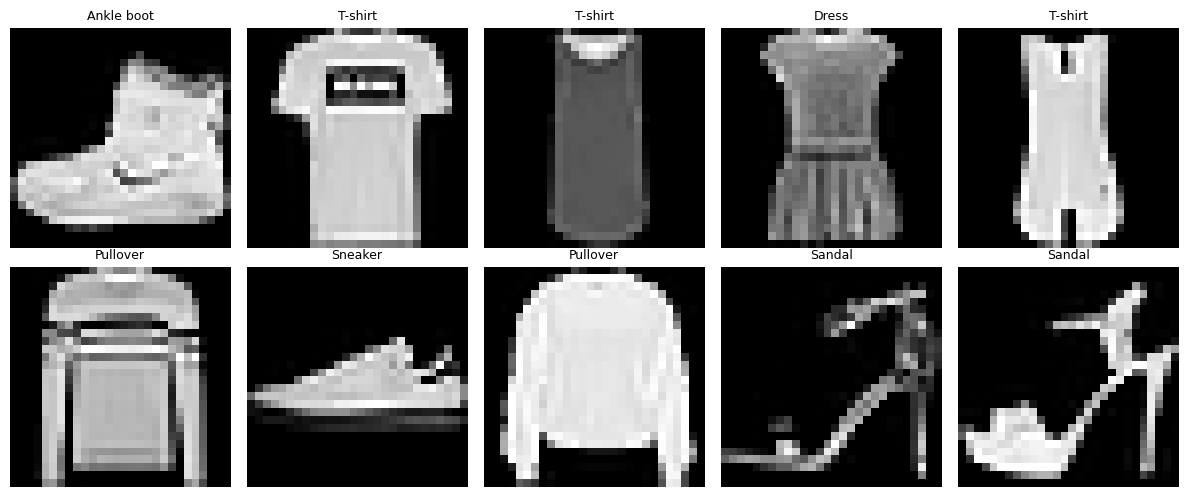

In [9]:
raw_train = datasets.FashionMNIST("data", train=True, download=True)

CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    img, label = raw_train[i]
    ax.imshow(img, cmap="gray")
    ax.set_title(CLASSES[label], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Step 2: Convert images to Tensors and build DataLoaders

In [10]:
to_tensor = transforms.ToTensor()                 # Convert images to Tensor

pixel_data = torch.stack([                        # Calculate Mean and Std
    to_tensor(img) for img, _ in raw_train
])
mean = pixel_data.mean().item()
std = pixel_data.std().item()

transform = transforms.Compose([
    transforms.ToTensor(),                        # Float tensor in [0,1], shape (1,28,28)
    transforms.Normalize((mean,), (std,))         # Normalize
])

full_train = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST("data", train=False, download=True, transform=transform)



train_set, val_set = random_split(                # 50k train / 10k validation split
    full_train,
     [50_000, 10_000],
    generator=torch.Generator().manual_seed(0))



BATCH = 128
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True)
val_loader = DataLoader(val_set, batch_size=1000)
test_loader = DataLoader(test_set, batch_size=1000)

xb, yb = next(iter(train_loader))
print("Batch shapes:", xb.shape, yb.shape)

Batch shapes: torch.Size([128, 1, 28, 28]) torch.Size([128])


### Step 3 & 4: Simple MLP with nn.Linear, plus Activation and Loss

In [11]:
class MLP(nn.Module):

    def __init__(self, hidden=(128, 64), p_drop=0.0):
        super().__init__()
        layers, in_dim = [nn.Flatten()], 28 * 28
        for h in hidden:
            layers += [nn.Linear(in_dim, h),
                       nn.ReLU()]                  # Step 4: activation
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))  # used in Step 10
            in_dim = h
        layers.append(nn.Linear(in_dim, 10))       # raw logits (no softmax here)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

# Step 4: CrossEntropyLoss
criterion = nn.CrossEntropyLoss()

### Step 5: Backprop with loss.backward() on a single batch

In [12]:
model = MLP().to(device)
xb, yb = xb.to(device), yb.to(device)

logits = model(xb)                    # forward pass
loss = criterion(logits, yb)          # loss
model.zero_grad()                     # clear old gradients
loss.backward()                       # backpropagation: fills p.grad for every parameter

print(f"\nInitial loss: {loss.item():.4f}\n")

for name, p in model.named_parameters():
    print(f"  grad norm of {name:12s}: {p.grad.norm():.4f}")


Initial loss: 2.3034

  grad norm of net.1.weight: 0.7537
  grad norm of net.1.bias  : 0.0228
  grad norm of net.3.weight: 0.2896
  grad norm of net.3.bias  : 0.0475
  grad norm of net.5.weight: 0.2061
  grad norm of net.5.bias  : 0.1173


### Helpers: evaluation (Step 8) and a generic training loop

In [13]:
@torch.no_grad()
def evaluate(model, loader): # Returns (average loss, accuracy) on a loader
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += criterion(out, y).item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def train(model, optimizer, train_loader, val_loader, epochs=5, verbose=True):
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for ep in range(1, epochs + 1):
        model.train()
        run_loss, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
        v_loss, v_acc = evaluate(model, val_loader)
        hist["train_loss"].append(run_loss / n)
        hist["train_acc"].append(correct / n)
        hist["val_loss"].append(v_loss)
        hist["val_acc"].append(v_acc)
        if verbose:
            print(f"  epoch {ep:2d} | train loss {run_loss/n:.4f} | "
                  f"val loss {v_loss:.4f} | val acc {v_acc:.4f}")
    return hist


def plot_curves(curves, key, title, ylabel=None):
    plt.figure(figsize=(6, 4))
    for label, hist in curves.items():
        plt.plot(range(1, len(hist[key]) + 1), hist[key], marker="o", label=label)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel or key)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### Step 6: Optimizers. First SGD, then Adam

SGD (lr=0.01)
  epoch  1 | train loss 1.3026 | val loss 0.7573 | val acc 0.7408
  epoch  2 | train loss 0.6514 | val loss 0.5917 | val acc 0.7841
  epoch  3 | train loss 0.5516 | val loss 0.5305 | val acc 0.8069
  epoch  4 | train loss 0.5037 | val loss 0.4947 | val acc 0.8225
  epoch  5 | train loss 0.4754 | val loss 0.4691 | val acc 0.8323

Adam (lr=0.001)
  epoch  1 | train loss 0.5383 | val loss 0.4156 | val acc 0.8459
  epoch  2 | train loss 0.3752 | val loss 0.3781 | val acc 0.8570
  epoch  3 | train loss 0.3378 | val loss 0.3409 | val acc 0.8720
  epoch  4 | train loss 0.3120 | val loss 0.3503 | val acc 0.8723
  epoch  5 | train loss 0.2890 | val loss 0.3281 | val acc 0.8804




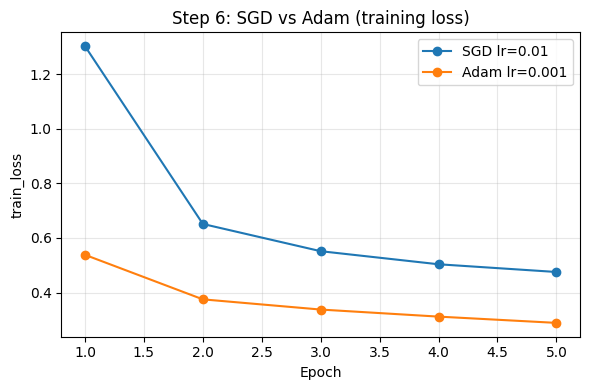

In [14]:
results6 = {}

torch.manual_seed(0)
m = MLP().to(device)
print("SGD (lr=0.01)")
results6["SGD lr=0.01"] = train(m, torch.optim.SGD(m.parameters(), lr=0.01),
                                train_loader, val_loader, epochs=5)

torch.manual_seed(0)
m = MLP().to(device)
print("\nAdam (lr=0.001)")
results6["Adam lr=0.001"] = train(m, torch.optim.Adam(m.parameters(), lr=1e-3),
                                  train_loader, val_loader, epochs=5)
print('\n')
plot_curves(results6, "train_loss", "Step 6: SGD vs Adam (training loss)")

### Step 7: Different learning rates and loss curves

  SGD  lr=0.001  -> final train loss 1.1963, val acc 0.6549
  SGD  lr=0.01   -> final train loss 0.4754, val acc 0.8323
  SGD  lr=0.1    -> final train loss 0.3241, val acc 0.8667
  SGD  lr=1.0    -> final train loss 1.5648, val acc 0.2812
  Adam lr=0.0001 -> final train loss 0.4090, val acc 0.8492
  Adam lr=0.001  -> final train loss 0.2890, val acc 0.8804
  Adam lr=0.01   -> final train loss 0.3449, val acc 0.8678
  Adam lr=0.1    -> final train loss 2.3081, val acc 0.0971


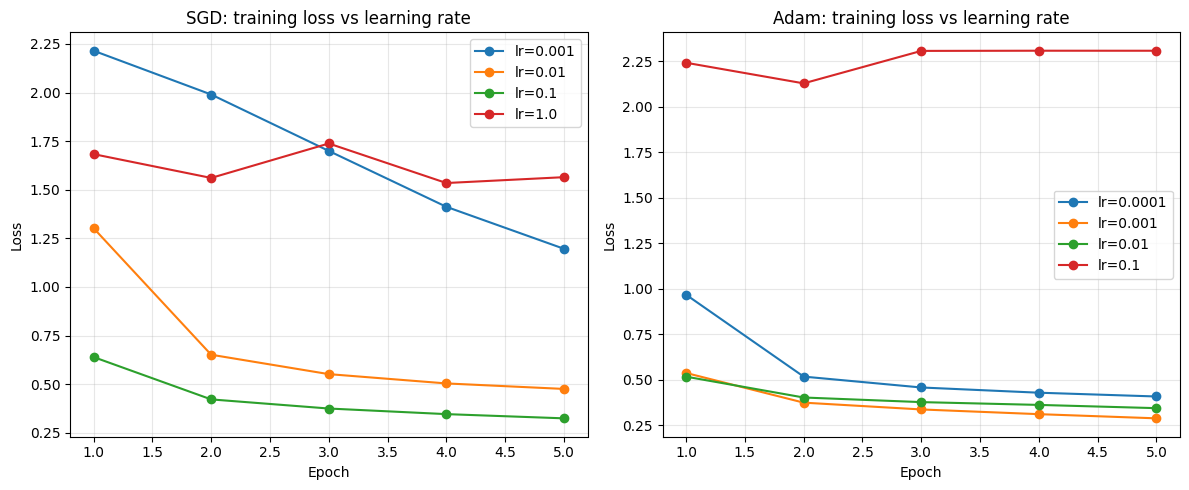

In [15]:
sweeps = {
    "SGD":  (lambda p, lr: torch.optim.SGD(p, lr=lr),  [0.001, 0.01, 0.1, 1.0]),
    "Adam": (lambda p, lr: torch.optim.Adam(p, lr=lr), [1e-4, 1e-3, 1e-2, 1e-1]),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (opt_name, (make_opt, lrs)) in zip(axes, sweeps.items()):
    for lr in lrs:
        torch.manual_seed(0)
        m = MLP().to(device)
        h = train(m, make_opt(m.parameters(), lr), train_loader, val_loader,
                  epochs=5, verbose=False)
        ax.plot(range(1, 6), h["train_loss"], marker="o", label=f"lr={lr}")
        print(f"  {opt_name:4s} lr={lr:<6} -> final train loss {h['train_loss'][-1]:.4f}, "
              f"val acc {h['val_acc'][-1]:.4f}")
    ax.set_title(f"{opt_name}: training loss vs learning rate")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Step 8: Validation accuracy (already tracked by evaluate/train)

  epoch  1 | train loss 0.5383 | val loss 0.4156 | val acc 0.8459
  epoch  2 | train loss 0.3752 | val loss 0.3781 | val acc 0.8570
  epoch  3 | train loss 0.3378 | val loss 0.3409 | val acc 0.8720
  epoch  4 | train loss 0.3120 | val loss 0.3503 | val acc 0.8723
  epoch  5 | train loss 0.2890 | val loss 0.3281 | val acc 0.8804
  epoch  6 | train loss 0.2746 | val loss 0.3333 | val acc 0.8786
  epoch  7 | train loss 0.2597 | val loss 0.3402 | val acc 0.8775
  epoch  8 | train loss 0.2496 | val loss 0.3170 | val acc 0.8842
  epoch  9 | train loss 0.2345 | val loss 0.3179 | val acc 0.8854
  epoch 10 | train loss 0.2249 | val loss 0.3102 | val acc 0.8882




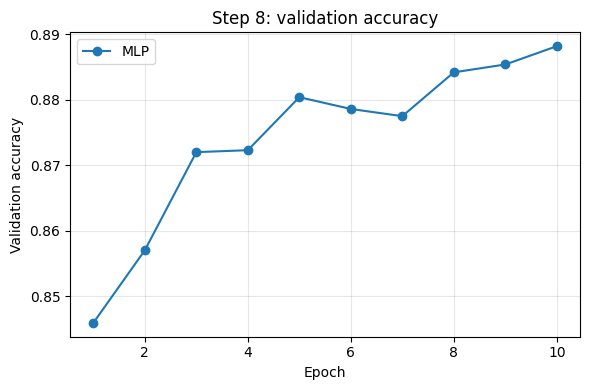


Final validation accuracy: 0.8882


In [16]:
torch.manual_seed(0)

base = MLP().to(device)

h_base = train(base, torch.optim.Adam(base.parameters(), lr=1e-3),
               train_loader, val_loader, epochs=10)

print('\n')

plot_curves({"MLP": h_base}, "val_acc", "Step 8: validation accuracy",
            ylabel="Validation accuracy")

print(f"\nFinal validation accuracy: {h_base['val_acc'][-1]:.4f}")

### Step 9: Create overfitting (big model + tiny training set)

  epoch  1 | train loss 1.2963 | val loss 0.9206 | val acc 0.6543
  epoch  2 | train loss 0.7221 | val loss 0.7217 | val acc 0.7382
  epoch  3 | train loss 0.5999 | val loss 0.6395 | val acc 0.7673
  epoch  4 | train loss 0.4288 | val loss 0.6140 | val acc 0.7837
  epoch  5 | train loss 0.4005 | val loss 0.6438 | val acc 0.7722
  epoch  6 | train loss 0.3466 | val loss 0.6700 | val acc 0.7760
  epoch  7 | train loss 0.2886 | val loss 0.6492 | val acc 0.7931
  epoch  8 | train loss 0.2596 | val loss 0.6295 | val acc 0.7960
  epoch  9 | train loss 0.2303 | val loss 0.8457 | val acc 0.7702
  epoch 10 | train loss 0.2364 | val loss 0.7111 | val acc 0.7894
  epoch 11 | train loss 0.2032 | val loss 0.7533 | val acc 0.7879
  epoch 12 | train loss 0.2412 | val loss 0.6725 | val acc 0.7940
  epoch 13 | train loss 0.1839 | val loss 0.7738 | val acc 0.7919
  epoch 14 | train loss 0.1473 | val loss 0.7223 | val acc 0.8019
  epoch 15 | train loss 0.0941 | val loss 0.7922 | val acc 0.8036
  epoch 16

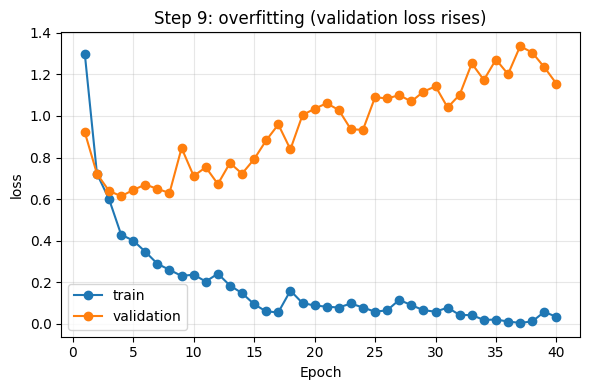

In [22]:
small_train = Subset(train_set, range(1000)) # only 1000 training images

small_loader = DataLoader(small_train, batch_size=64, shuffle=True)

BIG = (1024, 1024, 512)

torch.manual_seed(0)

big = MLP(hidden=BIG).to(device)

h_over = train(big, torch.optim.Adam(big.parameters(), lr=1e-3),
               small_loader, val_loader, epochs=40, verbose=True)

print(f"train acc {h_over['train_acc'][-1]:.4f} | val acc {h_over['val_acc'][-1]:.4f}"
      f" | val loss {h_over['val_loss'][-1]:.4f}\n")

plot_curves({"train": {"loss": h_over["train_loss"]}, "validation": {"loss": h_over["val_loss"]}},
            "loss", "Step 9: overfitting (validation loss rises)")

### Step 10: Partial fix with Dropout and weight_decay

  epoch  1 | train loss 1.6065 | val loss 0.9502 | val acc 0.6073
  epoch  2 | train loss 0.9522 | val loss 0.8173 | val acc 0.6712
  epoch  3 | train loss 0.7815 | val loss 0.7006 | val acc 0.7180
  epoch  4 | train loss 0.6532 | val loss 0.7052 | val acc 0.7147
  epoch  5 | train loss 0.6324 | val loss 0.6799 | val acc 0.7504
  epoch  6 | train loss 0.5869 | val loss 0.6093 | val acc 0.7702
  epoch  7 | train loss 0.5278 | val loss 0.6008 | val acc 0.7728
  epoch  8 | train loss 0.4714 | val loss 0.5986 | val acc 0.7833
  epoch  9 | train loss 0.4628 | val loss 0.6168 | val acc 0.7796
  epoch 10 | train loss 0.4524 | val loss 0.6226 | val acc 0.7787
  epoch 11 | train loss 0.4146 | val loss 0.6051 | val acc 0.7885
  epoch 12 | train loss 0.4065 | val loss 0.6211 | val acc 0.7938
  epoch 13 | train loss 0.3883 | val loss 0.7238 | val acc 0.7727
  epoch 14 | train loss 0.3852 | val loss 0.6521 | val acc 0.7894
  epoch 15 | train loss 0.3717 | val loss 0.6262 | val acc 0.7858
  epoch 16

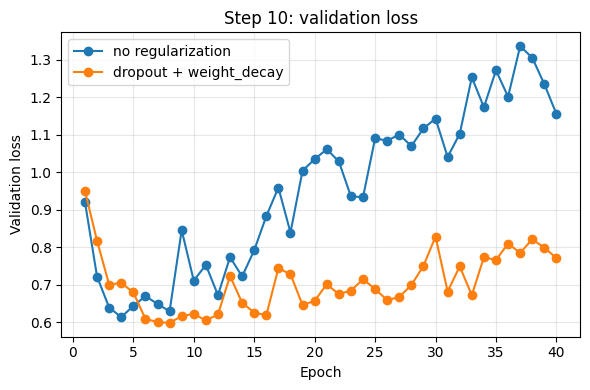


Gap (train acc - val acc): 0.191 -> 0.122


In [24]:
torch.manual_seed(0)

reg = MLP(hidden=BIG, p_drop=0.5).to(device)

opt = torch.optim.AdamW(reg.parameters(), lr=1e-3, weight_decay=0.05) # decoupled weight decay

h_reg = train(reg, opt, small_loader, val_loader, epochs=40, verbose=True)

print(f"train acc {h_reg['train_acc'][-1]:.4f} | val acc {h_reg['val_acc'][-1]:.4f} "
      f"| val loss {h_reg['val_loss'][-1]:.4f}\n")

plot_curves({"no regularization": {"v": h_over["val_loss"]},
             "dropout + weight_decay": {"v": h_reg["val_loss"]}},
            "v", "Step 10: validation loss", ylabel="Validation loss")

print("\nGap (train acc - val acc): "
      f"{h_over['train_acc'][-1] - h_over['val_acc'][-1]:.3f} -> "
      f"{h_reg['train_acc'][-1] - h_reg['val_acc'][-1]:.3f}")

### Step 11: Convert the MLP into a CNN (Conv2d + MaxPool2d)

In [25]:
class CNN(nn.Module):

    def __init__(self, p_drop=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),   # (1,28,28)  -> (32,28,28)
            nn.ReLU(),
            nn.MaxPool2d(2),                              #            -> (32,14,14)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  #            -> (64,14,14)
            nn.ReLU(),
            nn.MaxPool2d(2),                              #            -> (64,7,7)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                 #            -> 3136
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(model):
    return sum(p.numel() for p in model.parameters())

### Step 12: Final comparison (MLP vs CNN)

MLP  (235,146 parameters)
  epoch  1 | train loss 0.5015 | val loss 0.3914 | val acc 0.8549
  epoch  2 | train loss 0.3580 | val loss 0.3414 | val acc 0.8742
  epoch  3 | train loss 0.3179 | val loss 0.3413 | val acc 0.8738
  epoch  4 | train loss 0.2892 | val loss 0.3351 | val acc 0.8755
  epoch  5 | train loss 0.2715 | val loss 0.3193 | val acc 0.8851
  epoch  6 | train loss 0.2556 | val loss 0.3302 | val acc 0.8813
  epoch  7 | train loss 0.2376 | val loss 0.3260 | val acc 0.8800
  epoch  8 | train loss 0.2278 | val loss 0.3181 | val acc 0.8867
  epoch  9 | train loss 0.2143 | val loss 0.3135 | val acc 0.8880
  epoch 10 | train loss 0.2038 | val loss 0.3244 | val acc 0.8911
CNN  (421,642 parameters)
  epoch  1 | train loss 0.5250 | val loss 0.3669 | val acc 0.8626
  epoch  2 | train loss 0.3348 | val loss 0.2805 | val acc 0.8948
  epoch  3 | train loss 0.2863 | val loss 0.2574 | val acc 0.9042
  epoch  4 | train loss 0.2560 | val loss 0.2449 | val acc 0.9099
  epoch  5 | train loss 

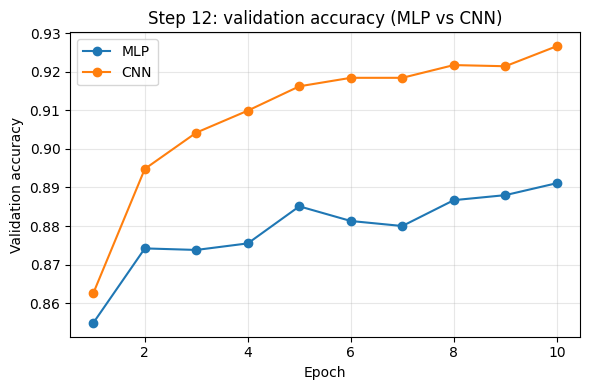

In [26]:
EPOCHS = 10
final = {}
curves = {}
for name, make in [("MLP", lambda: MLP(hidden=(256, 128))), ("CNN", lambda: CNN())]:
    torch.manual_seed(0)
    model = make().to(device)
    print(f"{name}  ({count_params(model):,} parameters)")
    h = train(model, torch.optim.Adam(model.parameters(), lr=1e-3),
              train_loader, val_loader, epochs=EPOCHS)
    t_loss, t_acc = evaluate(model, test_loader)
    final[name] = (count_params(model), h["val_acc"][-1], t_acc)
    curves[name] = h

print("\n" + "-" * 52)
print(f"{'Model':6s} {'Params':>10s} {'Val acc':>10s} {'Test acc':>10s}")
for name, (params, v, t) in final.items():
    print(f"{name:6s} {params:>10,} {v:>10.4f} {t:>10.4f}")
print("-" * 52)

plot_curves(curves, "val_acc", "Step 12: validation accuracy (MLP vs CNN)",
            ylabel="Validation accuracy")